200 simulated days, 11 bins
corr(distance to dock, base fill rate) = +0.29  (n=11, weak evidence either way)
 bin  base_rate  dock_min  share_days_hit_80  median_cross_min  tier
   3       45.7         4                1.0             150.0     1
  10       39.4         6                1.0             158.0     1
   4       37.6         5                1.0             170.0     1
   1       34.4         3                1.0             200.0     0
   5       34.4         5                1.0             187.0     1
   6       33.9         3                1.0             193.0     0
   2       33.1         5                1.0             192.0     1
   7       26.9         3                1.0             213.0     2
   9       25.4         6                1.0             228.0     1
   0       21.0         5                1.0             255.0     2
   8       20.3         1                1.0             254.0     2


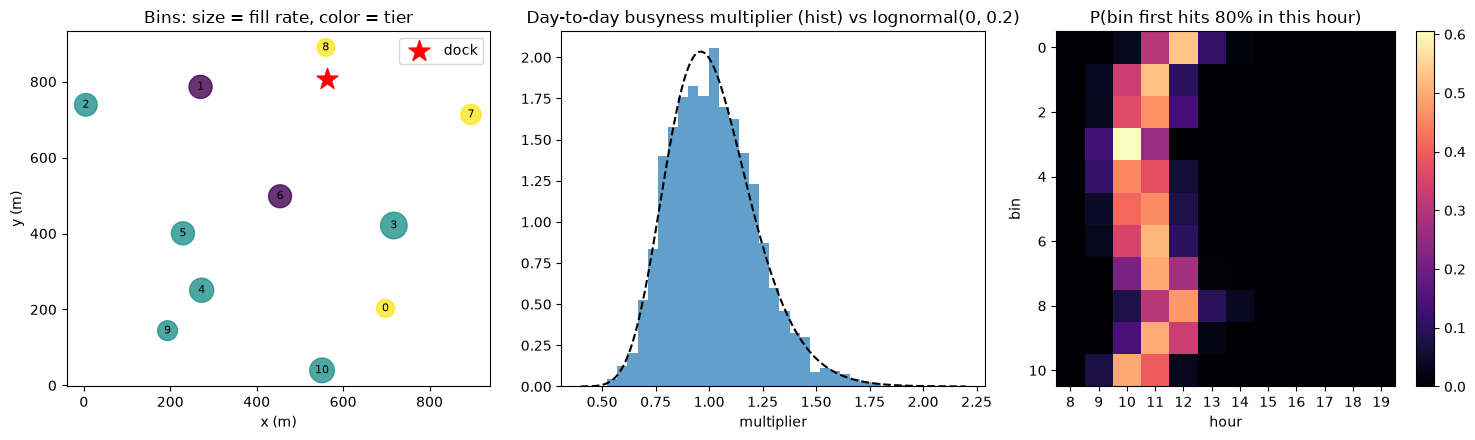

In [1]:
# %%
import math, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("results/figs", exist_ok=True)
plt.rcParams["figure.figsize"] = (9, 5)
QUICK = False
N_SEEDS = 40 if QUICK else 200

# ---- same world as the notebook (do not change, or results will not match) ----
_layout = np.random.default_rng(7)
N_NODES = 12
XY = _layout.uniform(0, 900, size=(N_NODES, 2))
SPEED = 130.0
T = np.ceil(np.linalg.norm(XY[:, None] - XY[None], axis=2) / SPEED).astype(int)
N_BINS = N_NODES - 1
BASE_RATE = _layout.uniform(20, 48, size=N_BINS)
DAY_MIN, START_HOUR = 720, 8


def demand_curve(h):
    return (0.25 + 1.2 * math.exp(-((h - 12.5) / 1.2) ** 2)
            + 0.6 * math.exp(-((h - 10.0) / 0.6) ** 2)
            + 0.6 * math.exp(-((h - 15.0) / 0.7) ** 2))


CURVE = np.array([demand_curve(START_HOUR + t / 60) for t in range(DAY_MIN)])


def fill_paths(seed, scale=1.0):
    """Fill level (%) of every bin every minute with NO robots: shape (DAY_MIN, N_BINS).
    Uses the same RNG draw order as simulate() so seed k is the same day."""
    rng = np.random.default_rng(seed)
    day_mult = rng.lognormal(0, 0.2, N_BINS)
    noise = np.clip(1 + 0.3 * rng.standard_normal((DAY_MIN, N_BINS)), 0, None)
    start = rng.uniform(0, 50, N_BINS)
    inc = BASE_RATE * day_mult * CURVE[:, None] * scale * noise / 60
    return np.minimum(start + np.cumsum(inc, axis=0), 100.0), day_mult


PATHS = [fill_paths(s)[0] for s in range(N_SEEDS)]
DAYMULT = np.array([fill_paths(s)[1] for s in range(N_SEEDS)])
print(f"{N_SEEDS} simulated days, {N_BINS} bins")

# %% [markdown]
# ## A. Demand EDA and service tiers  (sites.py / seed files)
# Questions: how uneven is demand across bins, does it depend on location, and do
# bins fall into natural groups that could drive priority or robot zoning?

# %%
dock_dist = T[0, 1:]                                  # minutes from dock to each bin
rate = BASE_RATE
r = np.corrcoef(dock_dist, rate)[0, 1]
print(f"corr(distance to dock, base fill rate) = {r:+.2f}  (n={N_BINS}, weak evidence either way)")

# time each bin first crosses 80% (NaN if it never does that day)
cross80 = np.full((N_SEEDS, N_BINS), np.nan)
for s, P in enumerate(PATHS):
    hit = P >= 80
    first = hit.argmax(axis=0)
    cross80[s] = np.where(hit.any(axis=0), first, np.nan)
per_bin = pd.DataFrame({
    "bin": np.arange(N_BINS), "base_rate": rate.round(1), "dock_min": dock_dist,
    "share_days_hit_80": (~np.isnan(cross80)).mean(axis=0).round(2),
    "median_cross_min": np.nanmedian(cross80, axis=0).round(0),
})

# simple k-means (k=3) on standardized (rate, dock distance) to get service tiers
feat = np.c_[rate, dock_dist]
Z = (feat - feat.mean(0)) / feat.std(0)
rng = np.random.default_rng(0)
cent = Z[rng.choice(N_BINS, 3, replace=False)]
for _ in range(50):
    lab = np.argmin(((Z[:, None] - cent[None]) ** 2).sum(2), axis=1)
    new = np.array([Z[lab == k].mean(0) if (lab == k).any() else cent[k] for k in range(3)])
    if np.allclose(new, cent):
        break
    cent = new
per_bin["tier"] = lab
per_bin.to_csv("results/per_bin_profile.csv", index=False)
print(per_bin.sort_values("base_rate", ascending=False).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
ax[0].scatter(XY[1:, 0], XY[1:, 1], s=rate * 8, c=lab, cmap="viridis", alpha=0.8)
ax[0].scatter(*XY[0], marker="*", s=250, c="red", label="dock")
for i in range(N_BINS):
    ax[0].annotate(str(i), XY[i + 1], ha="center", va="center", fontsize=8)
ax[0].set(title="Bins: size = fill rate, color = tier", xlabel="x (m)", ylabel="y (m)")
ax[0].legend()
ax[1].hist(DAYMULT.ravel(), bins=30, density=True, alpha=0.7)
xs = np.linspace(0.4, 2.2, 200)
ax[1].plot(xs, np.exp(-(np.log(xs) ** 2) / (2 * 0.2 ** 2)) / (xs * 0.2 * math.sqrt(2 * math.pi)), "k--")
ax[1].set(title="Day-to-day busyness multiplier (hist) vs lognormal(0, 0.2)", xlabel="multiplier")
hours = np.arange(START_HOUR, START_HOUR + 12)
heat = np.zeros((N_BINS, 12))
for s in range(N_SEEDS):
    for h in range(12):
        heat[:, h] += ((cross80[s] >= h * 60) & (cross80[s] < (h + 1) * 60))
im = ax[2].imshow(heat / N_SEEDS, aspect="auto", cmap="magma")
ax[2].set_xticks(range(12)); ax[2].set_xticklabels(hours)
ax[2].set(title="P(bin first hits 80% in this hour)", xlabel="hour", ylabel="bin")
plt.colorbar(im, ax=ax[2]); plt.tight_layout()
plt.savefig("results/figs/A_demand_eda.png", dpi=130); plt.show()